Dataset - https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package

Antes de correr o código descarregar o dataset e colocá-lo na drive numa pasta chamada 'AC', após esses passos correr o código

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
from seaborn import heatmap
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.neighbors import KNeighborsClassifier

##Load Data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

data = pd.read_csv(r"/content/drive/MyDrive/AC/weatherAUS.csv")

Mounted at /content/drive


In [3]:
data = data.dropna()
#Remove valores que não existem, missing data 

In [4]:
data['Date'], unique_dates = pd.factorize(data['Date'])
data['Location'], unique_locations = pd.factorize(data['Location'])
data['WindGustDir'], unique_wgds = pd.factorize(data['WindGustDir'])
data['WindDir9am'], unique_wd9s = pd.factorize(data['WindDir9am'])
data['WindDir3pm'], unique_wd3s = pd.factorize(data['WindDir3pm'])

#Factorize transforma strings em variáveis categoricas para valores distintos

data['RainToday'].replace(['No', 'Yes'],
                        [0, 1], inplace=True)
data['RainTomorrow'].replace(['No', 'Yes'],
                        [0, 1], inplace=True)

#Replace vai trocar o Yes e o No para 0,1.

<Axes: >

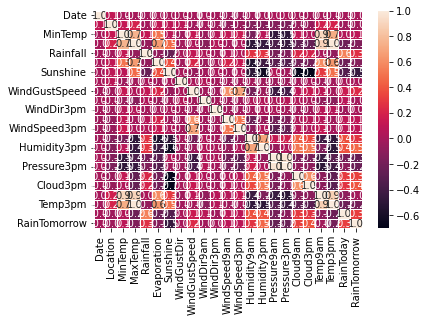

In [5]:
correlation = data.corr()

heatmap(correlation, annot = True, fmt=".1f", linewidths=.6)

#Matriz de correlação

In [6]:
for i in range(22): # 23 é o número de colunas, 22 para não apanhar o próprio RainTomorrow
  if abs(correlation['RainTomorrow'][i]) > 0.3:
    print(data.columns.values[i], '   >>>   ', correlation['RainTomorrow'][i])

#Maiores correlações em módulo com o valor que queremos prever o "Rain Tomorrow"

Sunshine    >>>    -0.4534069127165123
Humidity3pm    >>>    0.45535763701195064
Cloud9am    >>>    0.32397238104945836
Cloud3pm    >>>    0.38857421111885565
RainToday    >>>    0.30909822828617


##Train and Validation

In [7]:
#var_to_delete = ['Date','Location','MinTemp','MaxTemp','Rainfall','Evaporation','WindGustDir','WindGustSpeed','WindDir9am','WindDir3pm','WindSpeed9am','WindSpeed3pm','Humidity9am','Pressure9am','Pressure3pm','Temp9am','Temp3pm','RainTomorrow']
X = data.drop(['Date','Location','MinTemp','MaxTemp','Rainfall','Evaporation',
               'WindGustDir','WindGustSpeed','WindDir9am','WindDir3pm',
               'WindSpeed9am','WindSpeed3pm','Humidity9am','Pressure9am',
               'Pressure3pm','Temp9am','Temp3pm','RainTomorrow'], axis = 1)
y = data['RainTomorrow']

In [8]:
train_x, test_x, train_y, test_y = train_test_split(X, y, test_size = 0.25)

##DecisionTree

In [ ]:
clf = DecisionTreeClassifier(criterion = 'entropy', random_state=0)

clf.fit(train_x, train_y)

DecisionTreeClassifier(criterion='entropy', random_state=0)

In [ ]:
y_pred = clf.predict(test_x)

train_acc = accuracy_score(train_y, clf. predict(train_x))
test_acc = accuracy_score(test_y, y_pred)

print('Train data accuracy: ', train_acc.round(3)*100) 
print('Test data accuracy: ', test_acc.round(3)*100)

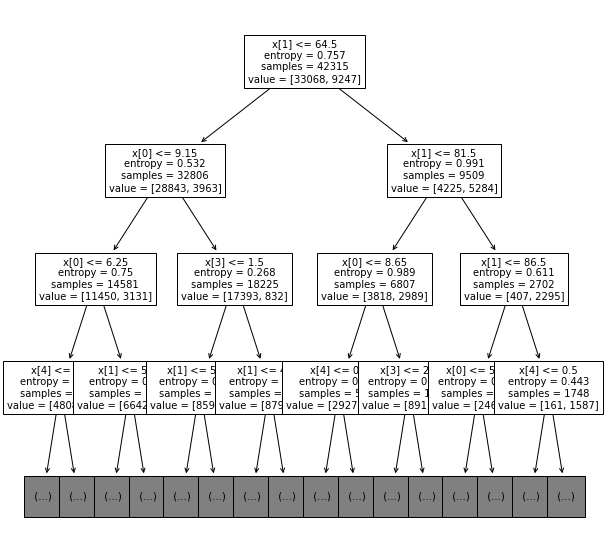

In [ ]:
plt.figure(figsize=(10,10))
tree.plot_tree(clf,fontsize=10, max_depth=3)
plt.show()

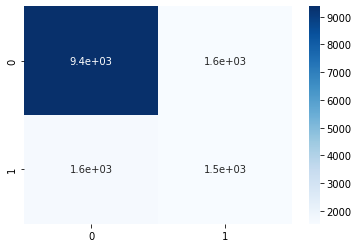

In [ ]:
cf_matrix = confusion_matrix(test_y,y_pred)
cf_matrix
ax = heatmap(cf_matrix, annot=True, cmap='Blues')

In [ ]:
train_accuracy = []
test_accuracy = []

for i in range(30): 
  train_x, test_x, train_y, test_y = train_test_split(X, y, test_size = 0.25)

  clf = DecisionTreeClassifier(criterion = 'entropy', random_state=0)
  clf.fit(train_x, train_y)
  
  y_pred = clf.predict(test_x)
  train_accuracy.append(accuracy_score(train_y, clf. predict(train_x)))
  test_accuracy.append(accuracy_score(test_y, y_pred))

In [ ]:
print('Train data accuracy (média de 30 vezes): ', (sum(train_accuracy)/len(train_accuracy)*100).round(3),'%') 
print('Test data accuracy (média de 30 vezes): ', (sum(test_accuracy)/len(test_accuracy)*100).round(3),'%')

Train data accuracy:  97.711 %
Test data accuracy:  77.322 %


# KNN

In [19]:
neigh = KNeighborsClassifier(n_neighbors=21)
neigh.fit(train_x,train_y)
knn = neigh.predict(test_x)

train_acc_knn = accuracy_score(train_y,neigh.predict(train_x))
test_acc_knn = accuracy_score(test_y,knn)

print("Train data accuracy: ",train_acc_knn.round(3)*100)
print("Test data accuracy: ",test_acc_knn.round(3)*100)

Train data accuracy:  88.5
Test data accuracy:  80.5


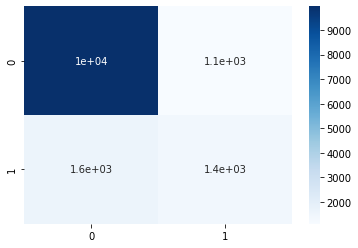

In [ ]:
cf_matrix = confusion_matrix(test_y,knn)
cf_matrix
ax = heatmap(cf_matrix, annot=True, cmap='Blues')

In [20]:
train_accuracy = []
test_accuracy = []

for i in range(30): 
  train_x, test_x, train_y, test_y = train_test_split(X, y, test_size = 0.25)

  neigh = KNeighborsClassifier(n_neighbors=21)
  neigh.fit(train_x,train_y)
  knn = neigh.predict(test_x)
  
  train_accuracy.append(accuracy_score(train_y, neigh. predict(train_x)))
  test_accuracy.append(accuracy_score(test_y, knn))

print('Train data accuracy (média de 30 vezes): ', (sum(train_accuracy)/len(train_accuracy)*100).round(3),'%') 
print('Test data accuracy (média de 30 vezes): ', (sum(test_accuracy)/len(test_accuracy)*100).round(3),'%')

Train data accuracy (média de 30 vezes):  84.268 %
Test data accuracy (média de 30 vezes):  83.266 %
